# Advanced Models

## Load Required Libraries and Dataset

In [1]:
#Import Required Libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from imblearn.combine import SMOTETomek
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from imblearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn import metrics
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.ensemble import RandomForestClassifier
from scipy.stats import randint, uniform
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import ConfusionMatrixDisplay
from imblearn.over_sampling import SMOTE

from xgboost import XGBClassifier

In [2]:
#Import data
df = pd.read_csv('../01_data/model_df.csv')
df.head()

,age,job,marital,education,default,housing,loan,contact,day,month,poutcome,y,contacted_before,balance_log,campaign_log,previous_log,age_bucket,balance_positive,long_campaign
0,58,management,married,tertiary,0,1,0,unknown,5,may,unknown,0,0,9.226607,0.693147,0.0,senior,1,0
1,44,technician,single,secondary,0,1,0,unknown,5,may,unknown,0,0,8.993427,0.693147,0.0,middle,1,0
2,33,entrepreneur,married,secondary,0,1,1,unknown,5,may,unknown,0,0,8.990068,0.693147,0.0,middle,1,0
3,47,blue-collar,married,unknown,0,1,0,unknown,5,may,unknown,0,0,9.161885,0.693147,0.0,middle,1,0
4,33,unknown,single,unknown,0,0,0,unknown,5,may,unknown,0,0,8.989943,0.693147,0.0,middle,1,0


## Preprocessing Pipeline

In [3]:
#Define numeric features that need to be scaled and categorical featurs that need OneHotEncoding
numeric_features = ['age', 'balance_log', 'previous_log']
categorical_features = [
    "job","education","marital","contact","poutcome", "day", "month","age_bucket"
]

#Create a preprocessing transformer variable
preprocessor = ColumnTransformer(
    transformers = [
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown = 'ignore'), categorical_features)
    ]
)

#Build the pipeline
pipeline = Pipeline(steps = [
    ('preprocess', preprocessor),
    ('smote', SMOTE(random_state = 42))
])

In [4]:
#Split data
X = df.drop('y', axis = 1)
y = df['y']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, random_state = 42)

## Random Forest

In [8]:
#Train split data on pipeline
pipeline_rfc = Pipeline(steps = [
    ('preprocess', preprocessor),
    ('smote', SMOTE(random_state = 42)),
    ('classifier', RandomForestClassifier(random_state = 42, n_jobs = -1))
])

pipeline_rfc.fit(X_train, y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'balance_log',
                                                   'previous_log']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['job', 'education',
                                                   'marital', 'contact',
                                                   'poutcome', 'day', 'month',
                                                   'age_bucket'])])),
                ('smote', SMOTE(random_state=42)),
                ('classifier',
                 RandomForestClassifier(n_jobs=-1, random_state=42))])

In [10]:
#Define hyperparamter search space - dictionary for the hyperparameter to tune and each value for a lost of possible settings to explore
param_dist_rfc = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [10, 20],
    'classifier__min_samples_split': [2, 5],
    'classifier__min_samples_leaf': [1, 2],
    'classifier__max_features': ['sqrt']
}

#Set up randomsearchcv to optimise for recall
random_search_rfc = RandomizedSearchCV(
    estimator = pipeline_rfc,
    param_distributions = param_dist_rfc,
    n_iter = 16,
    cv = 3, #uses 3-fold cross-validation
    random_state = 42
)

#Fit the tuning process
random_search_rfc.fit(X_train, y_train)

RandomizedSearchCV(cv=3,
                   estimator=Pipeline(steps=[('preprocess',
                                              ColumnTransformer(transformers=[('num',
                                                                               StandardScaler(),
                                                                               ['age',
                                                                                'balance_log',
                                                                                'previous_log']),
                                                                              ('cat',
                                                                               OneHotEncoder(handle_unknown='ignore'),
                                                                               ['job',
                                                                                'education',
                                                                                'marital',
                                                                                'contact',
                                                                                'poutcome',
                                                                                'day',
                                                                                'month',
                                                                                'age_bucket'])])),
                                             ('smote', SMOTE(random_state=42)),
                                             ('classifier',
                                              RandomForestClassifier(n_jobs=-1,
                                                                     random_state=42))]),
                   n_iter=16,
                   param_distributions={'classifier__max_depth': [10, 20],
                                        'classifier__max_features': ['sqrt'],
                                        'classifier__min_samples_leaf': [1, 2],
                                        'classifier__min_samples_split': [2, 5],
                                        'classifier__n_estimators': [100, 200]},
                   random_state=42)

In [15]:
#Print the results
print(random_search_rfc.best_params_)
print(random_search_rfc.best_score_)

#Find the best results from randomized search and make predictions based on these parameters
best_model_rfc =random_search_rfc.best_estimator_
y_pred_rfc = best_model_rfc.predict(X_test)

{'classifier__n_estimators': 200, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 20}
0.8777796216395619


### Evaluation

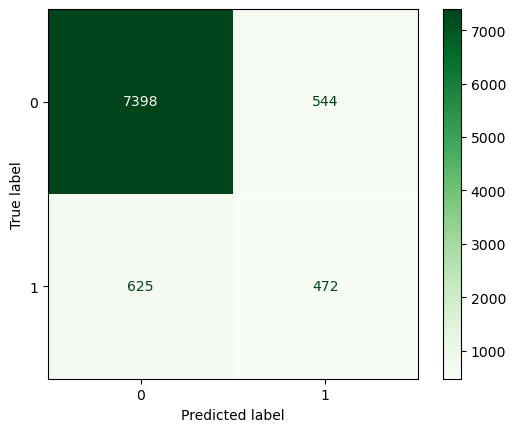

In [17]:
#Print confusion matrix
cm = confusion_matrix(y_test, y_pred_rfc)
ConfusionMatrixDisplay(confusion_matrix = cm).plot(cmap=plt.cm.Greens)

In [19]:
#Print evaluation metrics
print(classification_report(y_test, y_pred_rfc))

              precision    recall  f1-score   support

           0       0.92      0.93      0.93      7942
           1       0.46      0.43      0.45      1097

    accuracy                           0.87      9039
   macro avg       0.69      0.68      0.69      9039
weighted avg       0.87      0.87      0.87      9039



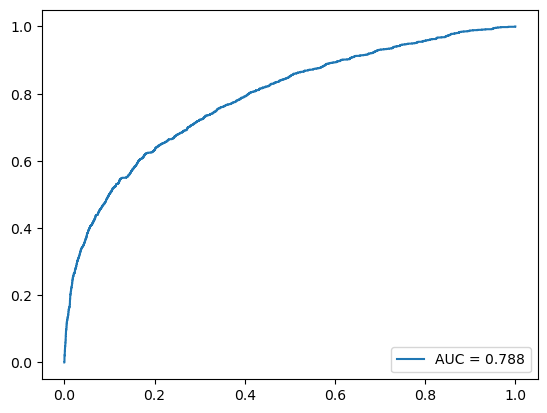

In [22]:
#Print ROC-AUC curve
y_pred_proba_rfc = best_model_rfc.predict_proba(X_test)[:,1]
fpr, tpr, _ = metrics.roc_curve(y_test, y_pred_proba_rfc)
auc = metrics.roc_auc_score(y_test, y_pred_proba_rfc)

plt.plot(fpr, tpr, label = "AUC = "+ str(round(auc,3)))
plt.legend(loc = 4)
plt.show()

## XGBoost

In [23]:
#Build the pipeline
pipeline_xgb = Pipeline(steps = [
    ('preprocess', preprocessor),
    ('smote', SMOTE(random_state = 42)),
    ('classifier', XGBClassifier(random_state = 42))
])

pipeline_xgb.fit(X_train, y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'balance_log',
                                                   'previous_log']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['job', 'education',
                                                   'marital', 'contact',
                                                   'poutcome', 'day', 'month',
                                                   'age_bucket'])])),
                ('smote', SMOTE(random_state=42)),
                ('classifier',
                 XGBClassifier(base_score=None, booster=None, callback...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=None,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=None,
                               num_parallel_tree=None, ...))])

In [26]:
#Hyperparamter Tuning
param_dist_xgb = {
    'classifier__n_estimators': [100, 200],
    'classifier__learning_rate': [0.05, 0.1],
    'classifier__max_depth': [3, 4],
    'classifier__subsample': [0.7, 1.0],
    'classifier__colsample_bytree': [0.7, 1.0],
    'classifier__gamma': [0, 0.1],
    'classifier__scale_pos_weight': [1, 3]
}

random_search_xgb = RandomizedSearchCV(
    estimator=pipeline_xgb,
    param_distributions=param_dist_xgb,
    n_iter=10,
    cv=3,
    random_state=42
)

random_search_xgb.fit(X_train, y_train)
print(random_search_xgb.best_params_)
print(random_search_xgb.best_estimator_)

{'classifier__subsample': 1.0, 'classifier__scale_pos_weight': 1, 'classifier__n_estimators': 200, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.05, 'classifier__gamma': 0, 'classifier__colsample_bytree': 1.0}
Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'balance_log',
                                                   'previous_log']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['job', 'education',
                                                   'marital', 'contact',
                                                   'poutcome', 'day', 'month',
                                                   'age_bucket'])])),
                ('smote', SMOTE(random_state=42)),
                ('classifier',
       

In [31]:
#Make predictions based on the best paramters
best_model_xgb = random_search_xgb.best_estimator_
y_pred_xgb = best_model_xgb.predict(X_test)

### Evaluation

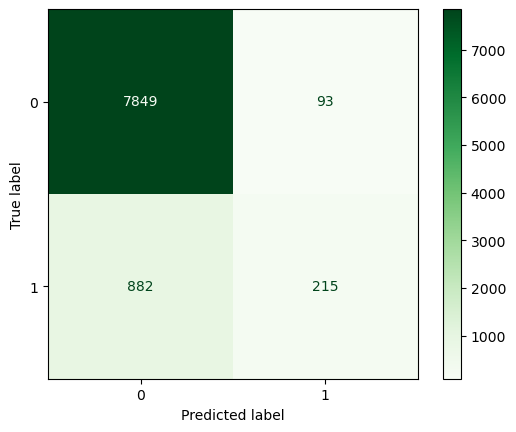

In [32]:
# confusion matrix
cm = confusion_matrix(y_test, y_pred_xgb)
ConfusionMatrixDisplay(confusion_matrix = cm).plot(cmap=plt.cm.Greens)

In [28]:
#Classification report
print(classification_report(y_test, y_pred_tuned_xgb))

              precision    recall  f1-score   support

           0       0.90      0.99      0.94      7942
           1       0.70      0.20      0.31      1097

    accuracy                           0.89      9039
   macro avg       0.80      0.59      0.62      9039
weighted avg       0.87      0.89      0.86      9039



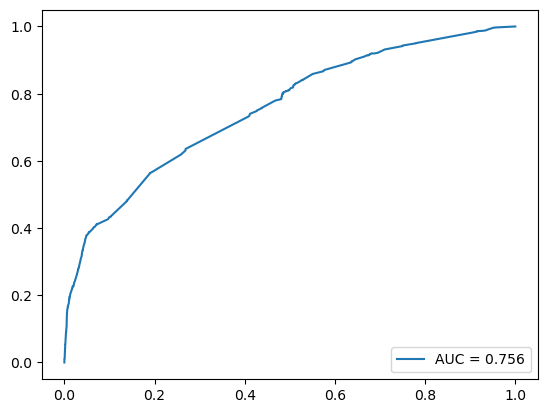

In [30]:
#ROC-AUC curve
y_pred_proba_xgb = best_model_xgb.predict_proba(X_test)[:,1]
fpr, tpr, _ = metrics.roc_curve(y_test, y_pred_proba_xgb)
auc = metrics.roc_auc_score(y_test, y_pred_proba_xgb)

plt.plot(fpr, tpr, label = "AUC = "+ str(round(auc,3)))
plt.legend(loc = 4)
plt.show()

## Model Comparison

|Model|Precision (yes)|Recall (yes)|F1 (yes)|Accuracy|
|-----|--------|---------|------|--|
|Logistic Regression|0.28|0.62|0.39|0.76|
|Random Forest|0.46|0.43|0.45|0.87|
|XGBoost|0.70|0.20|0.31|0.89|

**Chosen Model:** Random Forest Model

**Reasoning:**
* The Random Forest model offered the best overall balance when predicting the "yes" class, which is the key focus of this project.

* It achieved the highest recall in comparison to XGBoost and therefore successfully identified more actual responders than the other models - crucial for a marketing campaign where missing potential responders is costly.

* Its precision was better than logistic regression, meaning there were fewer false positives and more reliable predictions of who would actually respond.

* Furthermore, due to its consistent performance for precision and recall, it performs the highest F1-score for the "yes" class. This shows that it has a strong combined performance.

* Logistic Regression and XGBoost each excelling in only one area (Logistic Regression in recall, XGBoost in precision), but neither provided the balanced performance needed for effective targeting.

* Although the precision, recall, and F1-score for the "yes" class is below 0.55, this is expected for imbalanced classification problems like marketing response prediction - in this context, Random Forest's performance is strong and realistic.

* Therefore, Random Forest is the model that stands out as the most practical and dependable model for identifying likely responders and supporting targeted marketing decisions.